# Netflix Prize: Predicting Movie Ratings

## Business Problem
Given a customer's past ratings, can we predict the rating they will give a movie they have not seen yet? This is a **recommendation system** problem.

## Data
- ~100 million ratings, ~480K customers, 17,770 movies (1998 to 2005)
- Files: `combined_data_1-4.txt`, `movie_titles.csv`, `probe.txt`, `qualifying.txt`

## Success Metric
**RMSE** (root mean squared error). Lower is better.

## Roadmap
1. Setup and load data
2. Validate the load (data quality checks)
3. Exploratory data analysis (EDA)
4. Baseline model
5. Matrix factorization model
6. Evaluation

##  Libraries

In [1]:
import os                      
import gc                      
import warnings                

import numpy as np             
import pandas as pd            
import matplotlib.pyplot as plt  
import seaborn as sns

## Settings

In [2]:
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:,.4f}'.format)  # 4 decimals, thousands commas
sns.set_theme(style='whitegrid')

##  Paths

In [3]:
BASE = '/kaggle/input/datasets/netflix-inc/netflix-prize-data/'

print('Setup done')
print('pandas', pd.__version__, '| numpy', np.__version__)

Setup done
pandas 2.3.3 | numpy 2.1.3


## 1. Setup

**Goal:** Put all imports, settings and paths in one place, so the notebook has a single place to check its dependencies.

- Libraries: `pandas`, `numpy` for data, `matplotlib`, `seaborn` for charts
- `gc` lets us free memory, since the data is large (100M rows)
- `BASE` stores the data folder path once, so we never retype it

Modeling libraries will be added here later, when we reach the modeling phase.

In [4]:
def load_netflix(n):
    """Read combined_data_n.txt and return a tidy table."""
    # 1. read as plain text
    raw = pd.read_csv(BASE + f'combined_data_{n}.txt', header=None,
                      names=['customer_id', 'rating', 'date'], dtype=str)

    # 2. find movie lines (they have no rating) and read their IDs
    is_movie = raw['rating'].isna().to_numpy()
    pos = np.flatnonzero(is_movie)                               # row numbers of movie lines
    movie_ids = raw['customer_id'].iloc[pos].str[:-1].astype('int16').to_numpy()  # "1:" -> 1

    # 3. repeat each movie ID for all its rating rows
    counts = np.diff(np.append(pos, len(raw)))                   # block sizes
    raw['movie_id'] = np.repeat(movie_ids, counts)

    # 4. drop movie lines, convert to small types
    raw = raw[~is_movie]
    out = pd.DataFrame({
        'movie_id':    raw['movie_id'].to_numpy(),
        'customer_id': raw['customer_id'].astype('int32').to_numpy(),
        'rating':      raw['rating'].astype('int8').to_numpy(),
        'date':        pd.to_datetime(raw['date'], format='%Y-%m-%d'),
    })
    del raw
    gc.collect()
    return out

df1 = load_netflix(1); print('df1', df1.shape)
df2 = load_netflix(2); print('df2', df2.shape)
df3 = load_netflix(3); print('df3', df3.shape)
df4 = load_netflix(4); print('df4', df4.shape)

df1 (24053764, 4)
df2 (26977591, 4)
df3 (22601629, 4)
df4 (26847523, 4)


## 2. Load the Ratings

**Problem:** Each file mixes two kinds of lines: a movie line (`1:`) and rating lines (`customer_id, rating, date`). The movie ID is not a column, so we must copy it down onto every rating beneath it.

**Approach:** A *vectorized* method, not a slow line-by-line loop:
1. Read the file as plain text
2. Find the movie lines (they have no rating) and read their IDs
3. Repeat each ID for all of its rating rows
4. Drop the movie lines and convert columns to small data types

**Memory saving:** Smallest type that fits each column

| Column | Type | Why |
|---|---|---|
| `movie_id` | int16 | max 17,770 |
| `customer_id` | int32 | max ~2.6M |
| `rating` | int8 | values 1 to 5 |
| `date` | datetime64 | real dates |

**Result:** four tables, `df1` to `df4`, one per file.

**Check:** the four row counts should add up to **100,480,507**.

## 3. Data Quality Checks

**Goal:** Prove the loaded data is complete and sane before analysing it.

| # | Check | Expected |
|---|---|---|
| 1 | Total rows | 100,480,507 |
| 2 | Missing values | 0 |
| 3 | Value ranges | Ratings 1 to 5, dates 1998 to 2005, movie IDs 1 to 17,770 |
| 4 | Memory usage | About 1.5 GB total |

 Bad data in gives bad conclusions out. These checks are cheap and catch loading mistakes early.

In [5]:
dfs = {'df1': df1, 'df2': df2, 'df3': df3, 'df4': df4}

# Check 1: total rows
total = sum(len(d) for d in dfs.values())
print('CHECK 1 | total rows:', f'{total:,}', '->'  if total == 100_480_507 else 'MISMATCH')

# Check 2: missing values
print('\nCHECK 2 | missing values')
for name, d in dfs.items():
    print(' ', name, int(d.isna().sum().sum()))

# Check 3: value ranges
print('\nCHECK 3 | ranges')
for name, d in dfs.items():
    print(' ', name,
          '| movie', d['movie_id'].min(), '-', d['movie_id'].max(),
          '| rating', d['rating'].min(), '-', d['rating'].max(),
          '| date', d['date'].min().date(), 'to', d['date'].max().date())

# Check 4: memory
print('\nCHECK 4 | memory (GB)')
for name, d in dfs.items():
    print(' ', name, round(d.memory_usage(deep=True).sum() / 1e9, 2))

CHECK 1 | total rows: 100,480,507 ->

CHECK 2 | missing values
  df1 0
  df2 0
  df3 0
  df4 0

CHECK 3 | ranges
  df1 | movie 1 - 4499 | rating 1 - 5 | date 1999-11-11 to 2005-12-31
  df2 | movie 4500 - 9210 | rating 1 - 5 | date 1999-11-11 to 2005-12-31
  df3 | movie 9211 - 13367 | rating 1 - 5 | date 1999-11-11 to 2005-12-31
  df4 | movie 13368 - 17770 | rating 1 - 5 | date 1999-11-11 to 2005-12-31

CHECK 4 | memory (GB)
  df1 0.55
  df2 0.62
  df3 0.52
  df4 0.62


### 3b.  Fixing the Row Index

**Observation:** Tables used 23 bytes per row, but the column types add up to only 15.

**Hypothesis:** The loader kept the old row labels from the raw file as an 8-byte-per-row index.

**Test and fix:** Check the index type. If it is not a `RangeIndex`, reset it (the data itself does not change).

**Expected result:** about 1.5 GB total instead of 2.3 GB.

In [6]:
for name, d in dfs.items():
    print(name, 'index before:', type(d.index).__name__)
    if not isinstance(d.index, pd.RangeIndex):
        d.reset_index(drop=True, inplace=True)
    print(name, 'index after: ', type(d.index).__name__,
          '| memory GB:', round(d.memory_usage(deep=True).sum() / 1e9, 2))
gc.collect()

df1 index before: Index
df1 index after:  RangeIndex | memory GB: 0.36
df2 index before: Index
df2 index after:  RangeIndex | memory GB: 0.4
df3 index before: Index
df3 index after:  RangeIndex | memory GB: 0.34
df4 index before: Index
df4 index after:  RangeIndex | memory GB: 0.4


0

## 4. EDA

###  Rating Distribution

**Question:** How are the 100M ratings spread across 1 to 5 stars?

**Approach:** Count ratings inside each of the four tables and add the tallies, instead of merging 100M rows (saves memory). Show counts and percentages, and compute the overall mean.

**Why it matters:** The overall mean is the simplest possible prediction, and it will be our first baseline.

           count  percent
rating                   
1        4617990   4.5959
2       10132080  10.0836
3       28811247  28.6735
4       33750958  33.5896
5       23168232  23.0574

Global mean rating: 3.6043


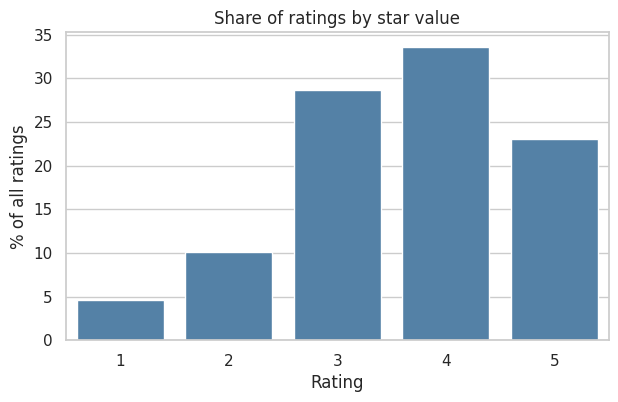

In [7]:
# count ratings in each table, then add the four tallies together
rating_counts = sum(d['rating'].value_counts() for d in dfs.values()).sort_index()

summary = pd.DataFrame({
    'count': rating_counts,
    'percent': rating_counts / rating_counts.sum() * 100
})
print(summary)

# overall mean = sum(rating x count) / total count
global_mean = (rating_counts.index * rating_counts).sum() / rating_counts.sum()
print('\nGlobal mean rating:', round(float(global_mean), 4))

# chart
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=summary.index, y=summary['percent'], ax=ax, color='steelblue')
ax.set_title('Share of ratings by star value')
ax.set_xlabel('Rating')
ax.set_ylabel('% of all ratings')
plt.show()

**Findings (4.1):**
- 4 stars is the most common rating (33.6%), then 3 (28.7%) and 5 (23.1%). 1 star is rarest (4.6%).
- Global mean is **3.6043**, below the most common value because the distribution is left-skewed.
- 85% of ratings are 3 or higher: users mostly rate movies they chose to watch (selection bias).
- Decision: first baseline predicts 3.6043; evaluate with RMSE.

### 4.2 Ratings Per Movie

**Question:** Do all movies get a similar number of ratings, or do a few dominate?

**Approach:** Movie IDs do not overlap between the four files, so group by movie inside each table and stack the four small results. This avoids merging 100M rows.

**Why it matters:** A movie's average is only trustworthy if it has enough ratings. This tells us how many movies are "thin".

**Chart:** Log-scale x-axis, because counts span several orders of magnitude.

shape: (17770, 2)
total ratings: 100,480,507
count    17,770.0000
mean      5,654.5024
std      16,909.6733
min           3.0000
10%         117.0000
25%         192.0000
50%         561.0000
75%       2,667.7500
90%      12,303.8000
99%      97,128.4300
max     232,944.0000
Name: count, dtype: float64

Top 10% of movies hold 76.6% of all ratings


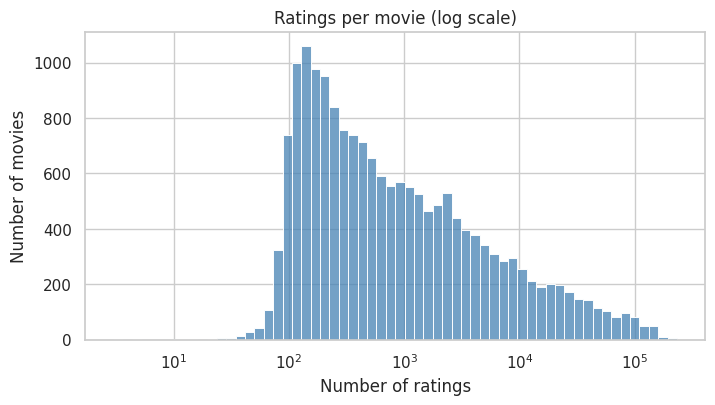

In [8]:
movie_stats = pd.concat(
    [d.groupby('movie_id')['rating'].agg(['count', 'mean']) for d in dfs.values()]
)

print('shape:', movie_stats.shape)
print('total ratings:', f"{int(movie_stats['count'].sum()):,}")
print(movie_stats['count'].describe(percentiles=[.1, .25, .5, .75, .9, .99]))

# share of all ratings held by the top 10% most-rated movies
sorted_counts = movie_stats['count'].sort_values(ascending=False)
top10_share = sorted_counts.iloc[:len(sorted_counts) // 10].sum() / sorted_counts.sum()
print(f"\nTop 10% of movies hold {top10_share:.1%} of all ratings")

# chart
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(movie_stats['count'], bins=60, log_scale=True, ax=ax, color='steelblue')
ax.set_title('Ratings per movie (log scale)')
ax.set_xlabel('Number of ratings')
ax.set_ylabel('Number of movies')
plt.show()

**Findings (4.2):**
- Ratings per movie are extremely skewed: median 561, mean 5,654, max 232,944.
- The top 10% of movies hold 76.6% of all ratings.
- Averages for thin movies (min is 3 ratings) are unreliable (about ±0.6 for n=3).
- Decision: use shrinkage toward the global mean in the baseline, and apply a minimum-count filter when ranking movies.

### 4.3 Ratings Per Customer

**Question:** Are customers equally active? How much does a customer's average rating differ from person to person?

**Approach:** Customers appear in all four files, so we cannot group per file and stack the results. Instead compute `count` and `sum` per customer in each file, add them across files, then compute `mean = sum / count`. (Averages of averages are wrong when group sizes differ.)

**Correctness test:** total sum / total count must equal the global mean (3.6043).

customers: 480,189
total ratings: 100,480,507
overall mean: 3.6043
count   480,189.0000
mean        209.2520
std         302.3392
min           1.0000
10%          19.0000
25%          39.0000
50%          96.0000
75%         259.0000
90%         541.0000
99%       1,390.0000
max      17,653.0000
Name: count, dtype: float64
count   480,189.0000
mean          3.6741
std           0.4730
min           1.0000
25%           3.3803
50%           3.6760
75%           3.9802
max           5.0000
Name: mean, dtype: float64


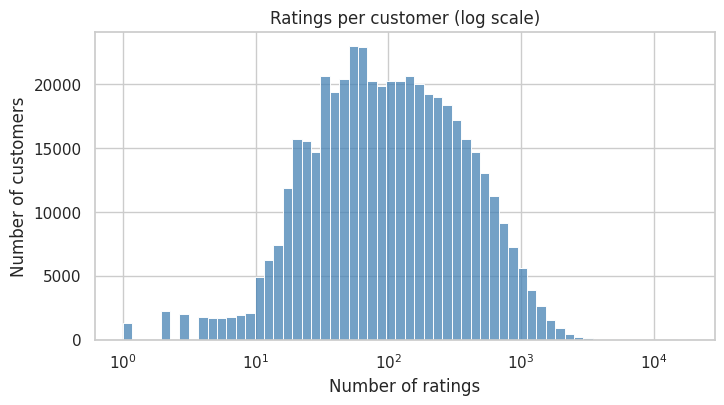

In [9]:
parts = [d.groupby('customer_id')['rating'].agg(['count', 'sum']) for d in dfs.values()]
cust_stats = pd.concat(parts).astype('int64').groupby(level=0).sum()
cust_stats['mean'] = cust_stats['sum'] / cust_stats['count']

# correctness tests
print('customers:', f"{len(cust_stats):,}")
print('total ratings:', f"{int(cust_stats['count'].sum()):,}")
print('overall mean:', round(cust_stats['sum'].sum() / cust_stats['count'].sum(), 4))

print(cust_stats['count'].describe(percentiles=[.1, .25, .5, .75, .9, .99]))
print(cust_stats['mean'].describe())

# chart: ratings per customer
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(cust_stats['count'], bins=60, log_scale=True, ax=ax, color='steelblue')
ax.set_title('Ratings per customer (log scale)')
ax.set_xlabel('Number of ratings')
ax.set_ylabel('Number of customers')
plt.show()